# Used Car Auction Sales Analysis: United States (2014–2015)

## 1. Project Overview

This project analyzes more than half a million used car sales at US auctions between December 2014 and July 2015. Used car auctions are where dealers, rental companies and finance companies buy and sell cars among themselves.

For each car sold, the file includes:

- make, model, trim, model year, body type and transmission;
- condition, odometer reading (miles), color and seller;
- the US state where it was sold and the sale date;
- the **selling price** and the **market value** (MMR, *Manheim Market Report*). The MMR is the reference value that Manheim, one of the largest auction companies in the US, calculates for each car based on previous sales.

Prices are in US dollars and distances in miles, as in the original file.

**Data source.** The file `car_prices.csv` was downloaded from Kaggle, where it is published as *Vehicle Sales Data* ([another project that uses the same file and links to the Kaggle page](https://github.com/aprilhong/vehiclesales)). I could not find a license or an official data dictionary, so the meaning of some columns (mainly condition) is inferred from the data itself, as explained in the cleaning section. The state boundaries used in the map come from [Natural Earth](https://www.naturalearthdata.com/), which is in the public domain.

**Questions**

1. Does the selling price follow the market value? When does it move away from it?
2. How much value does a car lose with age and mileage?
3. Which body types and makes sell the most, and at what price?
4. Which states have the most sales?

## 2. Imports and Configuration

- **pandas** to work with the data;
- **Matplotlib** and **seaborn** for the charts (seaborn makes box plots, violin plots, heatmaps and pair plots simpler);
- **geopandas** for the map.

In [1]:
# Show charts inside the notebook
%matplotlib inline

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter
import seaborn as sns
import geopandas as gpd

pd.set_option("display.max_columns", 30)

# Same look for every chart
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.titlesize": 12,
    "font.size": 10,
    "legend.frameon": False,
})

# Each car type always gets the same color; single-series charts use the neutral color
TYPE_COLORS = {"Sedan": "#2a78d6", "SUV": "#eb6834", "Pickup": "#1baf7a"}
NEUTRAL_COLOR = "#52514e"
LIGHT_COLOR = "#b5b4ae"

# Axis format with a thousands separator: 20000 -> 20,000
comma_format = StrMethodFormatter("{x:,.0f}")

## 3. Data Loading and Initial Inspection

In [2]:
# The CSV file is in the same folder as the notebook
raw = pd.read_csv("car_prices.csv")

print("Rows and columns:", raw.shape)
raw.head()

Rows and columns: (558837, 16)


,year,make,model,trim,body,transmission,vin,state,condition,odometer,color,interior,seller,mmr,sellingprice,saledate
0,2015,Kia,Sorento,LX,SUV,automatic,5xyktca69fg566472,ca,5.0,16639.0,white,black,kia motors america inc,20500.0,21500.0,Tue Dec 16 2014 12:30:00 GMT-0800 (PST)
1,2015,Kia,Sorento,LX,SUV,automatic,5xyktca69fg561319,ca,5.0,9393.0,white,beige,kia motors america inc,20800.0,21500.0,Tue Dec 16 2014 12:30:00 GMT-0800 (PST)
2,2014,BMW,3 Series,328i SULEV,Sedan,automatic,wba3c1c51ek116351,ca,45.0,1331.0,gray,black,financial services remarketing (lease),31900.0,30000.0,Thu Jan 15 2015 04:30:00 GMT-0800 (PST)
3,2015,Volvo,S60,T5,Sedan,automatic,yv1612tb4f1310987,ca,41.0,14282.0,white,black,volvo na rep/world omni,27500.0,27750.0,Thu Jan 29 2015 04:30:00 GMT-0800 (PST)
4,2014,BMW,6 Series Gran Coupe,650i,Sedan,automatic,wba6b2c57ed129731,ca,43.0,2641.0,gray,black,financial services remarketing (lease),66000.0,67000.0,Thu Dec 18 2014 12:30:00 GMT-0800 (PST)


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 558837 entries, 0 to 558836
Data columns (total 16 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   year          558837 non-null  int64  
 1   make          548536 non-null  str    
 2   model         548438 non-null  str    
 3   trim          548186 non-null  str    
 4   body          545642 non-null  str    
 5   transmission  493485 non-null  str    
 6   vin           558833 non-null  str    
 7   state         558837 non-null  str    
 8   condition     547017 non-null  float64
 9   odometer      558743 non-null  float64
 10  color         558088 non-null  str    
 11  interior      558088 non-null  str    
 12  seller        558837 non-null  str    
 13  mmr           558799 non-null  float64
 14  sellingprice  558825 non-null  float64
 15  saledate      558825 non-null  str    
dtypes: float64(4), int64(1), str(11)
memory usage: 68.2 MB


In [4]:
# Missing values per column
raw.isna().sum()

year                0
make            10301
model           10399
trim            10651
body            13195
transmission    65352
vin                 4
state               0
condition       11820
odometer           94
color             749
interior          749
seller              0
mmr                38
sellingprice       12
saledate           12
dtype: int64

In [5]:
print("Duplicated rows:", raw.duplicated().sum())
print("Repeated VINs:", raw["vin"].duplicated().sum())

Duplicated rows: 0
Repeated VINs: 8539


In [6]:
raw[["year", "condition", "odometer", "mmr", "sellingprice"]].describe().round(1)

,year,condition,odometer,mmr,sellingprice
count,558837.0,547017.0,558743.0,558799.0,558825.0
mean,2010.0,30.7,68320.0,13769.4,13611.4
std,4.0,13.4,53398.5,9680.0,9749.5
min,1982.0,1.0,1.0,25.0,1.0
25%,2007.0,23.0,28371.0,7100.0,6900.0
50%,2012.0,35.0,52254.0,12250.0,12100.0
75%,2013.0,42.0,99109.0,18300.0,18200.0
max,2015.0,49.0,999999.0,182000.0,230000.0


Four things in this table look wrong:

- condition goes from 1 to 49, when a short scale would be expected;
- there is a car with 999,999 miles;
- some cars sold for $1;
- the highest selling price ($230,000) is higher than the highest market value.

I look at these and other issues in the text columns below.

In [7]:
# Transmission should only be "automatic" or "manual"
raw["transmission"].value_counts(dropna=False)

transmission
automatic    475915
NaN           65352
manual        17544
sedan            15
Sedan            11
Name: count, dtype: int64

In [8]:
# State should only contain US state codes
print(raw["state"].nunique(), "different values")
print(sorted(raw["state"].unique()))

64 different values
['3vwd17aj0fm227318', '3vwd17aj2fm258506', '3vwd17aj2fm261566', '3vwd17aj2fm285365', '3vwd17aj3fm259017', '3vwd17aj3fm276741', '3vwd17aj4fm201708', '3vwd17aj4fm236636', '3vwd17aj5fm206111', '3vwd17aj5fm219943', '3vwd17aj5fm221322', '3vwd17aj5fm225953', '3vwd17aj5fm268964', '3vwd17aj5fm273601', '3vwd17aj5fm297123', '3vwd17aj6fm218641', '3vwd17aj6fm231972', '3vwd17aj7fm218440', '3vwd17aj7fm222388', '3vwd17aj7fm223475', '3vwd17aj7fm229552', '3vwd17aj7fm326640', '3vwd17aj8fm239622', '3vwd17aj8fm298895', '3vwd17aj9fm219766', '3vwd17ajxfm315938', 'ab', 'al', 'az', 'ca', 'co', 'fl', 'ga', 'hi', 'il', 'in', 'la', 'ma', 'md', 'mi', 'mn', 'mo', 'ms', 'nc', 'ne', 'nj', 'nm', 'ns', 'nv', 'ny', 'oh', 'ok', 'on', 'or', 'pa', 'pr', 'qc', 'sc', 'tn', 'tx', 'ut', 'va', 'wa', 'wi']


In [9]:
sorted(raw["condition"].dropna().unique())

[np.float64(1.0),
 np.float64(2.0),
 np.float64(3.0),
 np.float64(4.0),
 np.float64(5.0),
 np.float64(11.0),
 np.float64(12.0),
 np.float64(13.0),
 np.float64(14.0),
 np.float64(15.0),
 np.float64(16.0),
 np.float64(17.0),
 np.float64(18.0),
 np.float64(19.0),
 np.float64(21.0),
 np.float64(22.0),
 np.float64(23.0),
 np.float64(24.0),
 np.float64(25.0),
 np.float64(26.0),
 np.float64(27.0),
 np.float64(28.0),
 np.float64(29.0),
 np.float64(31.0),
 np.float64(32.0),
 np.float64(33.0),
 np.float64(34.0),
 np.float64(35.0),
 np.float64(36.0),
 np.float64(37.0),
 np.float64(38.0),
 np.float64(39.0),
 np.float64(41.0),
 np.float64(42.0),
 np.float64(43.0),
 np.float64(44.0),
 np.float64(45.0),
 np.float64(46.0),
 np.float64(47.0),
 np.float64(48.0),
 np.float64(49.0)]

In [10]:
# The least common makes show the same brand written in different ways
print(raw["make"].nunique(), "different makes")
raw["make"].value_counts().tail(15)

96 different makes


make
plymouth       7
suzuki         5
Lamborghini    4
maserati       3
Daewoo         3
ford truck     3
mercedes-b     2
dodge tk       1
mazda tk       1
hyundai tk     1
chev truck     1
ford tk        1
airstream      1
dot            1
Lotus          1
Name: count, dtype: int64

In [11]:
print(raw["body"].nunique(), "different body types")
raw["body"].value_counts().head(12)

87 different body types


body
Sedan          199437
SUV            119292
sedan           41906
suv             24552
Hatchback       21380
Minivan         21363
Coupe           14602
Wagon           13630
Crew Cab        13280
Convertible      8652
SuperCrew        7423
G Sedan          5999
Name: count, dtype: int64

**Inspection summary**

- **Misaligned rows:** transmission has 26 "sedan" values, and the state column has VINs instead of state codes. These are the same 26 rows, where the values shifted one column to the right.
- **States:** besides US states, there is Puerto Rico (`pr`) and four Canadian provinces (`ab`, `on`, `qc`, `ns`).
- **Condition:** there are values from 1 to 5 and from 11 to 49.
- **Makes and body types:** the same names are written in different ways ("Ford", "ford", "ford tk"; "Sedan", "sedan"). There are 96 make names and 87 body names.
- **Missing values:** transmission is missing in 65,352 rows (12%), and make, model, body and condition in about 2%. Price and sale date are missing in 12 rows.
- **Repeated VINs:** 8,539 rows have a VIN that already appeared. I check in the cleaning section whether they are duplicates or resales.
- There are no fully duplicated rows.

## 4. Data Cleaning and Preparation

All cleaning is done on a copy (`cars`). The original table (`raw`) and the CSV file stay unchanged. I rename the four columns whose names are not clear (`year`, `mmr`, `sellingprice`, `saledate`) and keep the others as they are.

In [12]:
cars = raw.rename(columns={
    "year": "model_year",        # to avoid confusion with the year of the sale
    "mmr": "market_value",       # Manheim Market Report value
    "sellingprice": "selling_price",
    "saledate": "sale_date",
})
initial_rows = len(cars)

### 4.1 Misaligned rows

In [13]:
misaligned = cars["transmission"].isin(["sedan", "Sedan"])
cars[misaligned].head(3)

,model_year,make,model,trim,body,transmission,vin,state,condition,odometer,color,interior,seller,market_value,selling_price,sale_date
408161,2015,Volkswagen,Jetta,SE PZEV w/Connectivity,Navitgation,Sedan,automatic,3vwd17aj4fm201708,NaN,46.0,4802,silver,gray,NaN,13200.0,16500
417835,2015,Volkswagen,Jetta,SE PZEV w/Connectivity,Navitgation,Sedan,automatic,3vwd17aj2fm258506,NaN,1.0,9410,white,gray,NaN,13300.0,10500
421289,2015,Volkswagen,Jetta,SE PZEV w/Connectivity,Navitgation,Sedan,automatic,3vwd17aj3fm276741,NaN,46.0,1167,blue,black,NaN,13200.0,12700


In these rows, the body type is in the transmission column, the transmission in the VIN column, the VIN in the state column, and so on. They could be fixed by hand, but there are only 26 of them, all the same model (2015 VW Jetta), so I remove them.

In [14]:
cars = cars[~misaligned]
print("Rows removed:", misaligned.sum(), "| rows left:", len(cars))

Rows removed: 26 | rows left: 558811


### 4.2 Missing price, market value or sale date

These are the main columns of the analysis. A row without them is not usable, and it would make no sense to invent a price.

In [15]:
rows_before = len(cars)
cars = cars.dropna(subset=["selling_price", "market_value", "sale_date"])
print("Rows removed:", rows_before - len(cars), "| rows left:", len(cars))

Rows removed: 12 | rows left: 558799


### 4.3 Impossible prices

In [16]:
# Sold for less than $100, or for more than 5 times the market value and above $50,000
impossible_price = (cars["selling_price"] < 100) | (
    (cars["selling_price"] > 5 * cars["market_value"]) & (cars["selling_price"] > 50000)
)
cars.loc[impossible_price, ["model_year", "make", "model", "odometer", "market_value", "selling_price"]]

,model_year,make,model,odometer,market_value,selling_price
7566,2002,Ford,F-350 Super Duty,NaN,7850.0,1.0
48453,2003,Mercedes-Benz,E-Class,1.0,7325.0,1.0
160201,2010,Ford,Escape,82985.0,8250.0,108200.0
293223,2014,Ford,E-Series Van,31886.0,20800.0,1.0
344905,2014,Ford,Escape,27802.0,22800.0,230000.0
348252,1995,Isuzu,Rodeo,254132.0,375.0,1.0
407508,2012,Nissan,Versa,10926.0,10350.0,67500.0


Four cars sold for $1, and three sold for a price that seems to have an extra digit. A 2014 Ford Escape with a market value of $22,800 was "sold" for $230,000, and a Nissan Versa worth $10,350 for $67,500. These are recording errors, so I remove these 7 rows.

I keep the other low and high prices. Many old cars have market values of a few hundred dollars, where a $300 difference looks huge in percentage terms but is normal.

In [17]:
cars = cars[~impossible_price]
print("Rows removed:", impossible_price.sum(), "| rows left:", len(cars))

Rows removed: 7 | rows left: 558792


### 4.4 Sales in Canada

Besides the US states and Puerto Rico, there are sales in four Canadian provinces (`ab`, `on`, `qc`, `ns`). The file does not say which currency prices are in. Since these could be in Canadian dollars, I remove them so that currencies are not mixed.

In [18]:
canada_provinces = ["ab", "on", "qc", "ns"]
in_canada = cars["state"].isin(canada_provinces)
cars = cars[~in_canada]
print("Rows removed:", in_canada.sum(), "| rows left:", len(cars))

Rows removed: 5676 | rows left: 553116


### 4.5 Odometer

In [19]:
print("Cars with 999,999 miles:", (cars["odometer"] == 999999).sum())

# 999999 is a placeholder, not a real reading, so it becomes a missing value
cars.loc[cars["odometer"] == 999999, "odometer"] = None

Cars with 999,999 miles: 72


### 4.6 Condition

Condition has values from 1 to 5 and from 11 to 49. My guess is that it is all one 1–5 scale, sometimes written with the decimal point removed (35 = 3.5). If so, the values 10, 20, 30, 40 and 50 should exist. I check whether they do, and compare the price of each whole grade with its neighbors (for example, 2 with 19 and 21). The table lists the values in the order they would have on a 1–5 scale: 1; 1.1; 1.9; 2; 2.1; ...

In [20]:
print("Cars with condition 10, 20, 30, 40 or 50:", cars["condition"].isin([10, 20, 30, 40, 50]).sum())

# Median price for each whole grade and its neighbors, in the order of a 1-5 scale
price_by_condition = cars.groupby("condition")["selling_price"].median()
price_by_condition.loc[[1, 11, 19, 2, 21, 29, 3, 31, 39, 4, 41, 49, 5]]

Cars with condition 10, 20, 30, 40 or 50: 0


condition
1.0      1700.0
11.0     3100.0
19.0     3600.0
2.0      3700.0
21.0     5800.0
29.0     9600.0
3.0     11800.0
31.0    10500.0
39.0    14000.0
4.0     16500.0
41.0    15100.0
49.0    20500.0
5.0     22000.0
Name: selling_price, dtype: float64

The values 10, 20, 30, 40 and 50 never appear, and 1, 2, 3, 4 and 5 appear in their place. The prices fit as well: cars with grade 2 sell for almost the same as cars with 19, and for less than cars with 21. For grades 3, 4 and 5, the whole grades are a little above their neighbors, but always close to them and in the right order (the better the grade, the more expensive the car).

I conclude that the scale runs from 1 to 5 with one decimal: 2 means 2.0 and 35 means 3.5. This is inferred from the data, not stated by the source.

In [21]:
# Values of 10 and above move to the 1-5 scale (35 -> 3.5)
ten_scale = cars["condition"] >= 10
cars.loc[ten_scale, "condition"] = cars.loc[ten_scale, "condition"] / 10

# Whole grade for comparing groups: 3.5 counts as grade 3
cars["condition_grade"] = cars["condition"] // 1
cars["condition"].describe().round(2)

count    541524.00
mean          3.42
std           0.95
min           1.00
25%           2.70
50%           3.60
75%           4.20
max           5.00
Name: condition, dtype: float64

### 4.7 Sale date and car age

The sale date is stored as text (`Tue Dec 16 2014 12:30:00 GMT-0800 (PST)`). I only use the day, month and year.

In [22]:
# The first 15 characters hold the weekday, month, day and year ("Tue Dec 16 2014")
cars["sale_date"] = pd.to_datetime(cars["sale_date"].str[:15], format="%a %b %d %Y")
print("First sale:", cars["sale_date"].min().date(), "| last sale:", cars["sale_date"].max().date())

# Sales per month
cars["sale_date"].dt.to_period("M").value_counts().sort_index()

First sale: 2014-01-01 | last sale: 2015-07-21


sale_date
2014-01       206
2014-02         1
2014-12     53090
2015-01    139109
2015-02    161809
2015-03     45878
2015-04      1436
2015-05     51735
2015-06     98570
2015-07      1282
Freq: M, Name: count, dtype: int64

Almost all sales are between December 2014 and June 2015. The number of sales per month is very uneven: April has 1,436 and June has 98,570. This does not look like a real market pattern; more likely, the file does not contain every month in full. For this reason **I do not analyze sales month by month**, and use the age of the car as the time variable instead. The 207 sales from January and February 2014 are also odd, but there are too few of them to affect the results.

In [23]:
# Age = year of sale - model year.
# A 2015 model sold in December 2014 would give -1, so it counts as 0 (new car).
cars["age"] = (cars["sale_date"].dt.year - cars["model_year"]).clip(lower=0)
cars["age"].describe().round(1)

count    553116.0
mean          4.9
std           3.9
min           0.0
25%           2.0
50%           3.0
75%           7.0
max          33.0
Name: age, dtype: float64

### 4.8 Makes

In [24]:
# Lower case everything, then merge the variants of the same brand
make_fixes = {
    "chev truck": "chevrolet",
    "dodge tk": "dodge",
    "ford tk": "ford",
    "ford truck": "ford",
    "gmc truck": "gmc",
    "hyundai tk": "hyundai",
    "mazda tk": "mazda",
    "landrover": "land rover",
    "mercedes": "mercedes-benz",
    "mercedes-b": "mercedes-benz",
    "vw": "volkswagen",
}
cars["make"] = cars["make"].str.lower().replace(make_fixes)
print("Different makes after cleaning:", cars["make"].nunique())

Different makes after cleaning: 55


### 4.9 Body types

There are dozens of body names, many repeated in upper and lower case, and more than ten just for pickups ("crew cab", "supercab", "quad cab"...). I group them into main types by looking for keywords in the name.

In [25]:
body = cars["body"].str.lower()

# Keyword in the body name -> car type.
# Order matters: later rules overwrite earlier ones, so "minivan" must come after "van".
body_keywords = {
    "sedan": "Sedan",
    "suv": "SUV",
    "cab|crew": "Pickup",
    "coupe|koup": "Coupe",
    "convertible": "Convertible",
    "wagon": "Wagon",
    "hatchback": "Hatchback",
    "van": "Van",
    "minivan": "Minivan",
}

cars["car_type"] = None  # stays empty when the body is unknown or matches no keyword
for keyword, car_type in body_keywords.items():
    cars.loc[body.str.contains(keyword, na=False), "car_type"] = car_type

cars["car_type"].value_counts(dropna=False)

car_type
Sedan          246969
SUV            142399
Pickup          47047
Hatchback       25970
Minivan         25013
Coupe           20111
Wagon           16002
None            12315
Convertible     10871
Van              6419
Name: count, dtype: int64

### 4.10 Repeated VINs

The VIN (vehicle identification number) is unique to each car. Some cars appear more than once.

In [26]:
repeated_vin = cars["vin"].duplicated(keep=False)
print("Cars that appear more than once:", cars.loc[repeated_vin, "vin"].nunique())

# One example
example_vin = cars.loc[repeated_vin, "vin"].iloc[0]
cars.loc[cars["vin"] == example_vin, ["vin", "make", "model", "odometer", "selling_price", "sale_date"]]

Cars that appear more than once: 8230


,vin,make,model,odometer,selling_price,sale_date
21,wba5a5c51ed501631,bmw,5 Series,25969.0,30000.0,2015-02-03
325807,wba5a5c51ed501631,bmw,5 Series,26018.0,31000.0,2015-02-19


The same car appears on different dates, with more miles at the second sale. These are real resales, which happen at auctions when a car is not collected or is put up for sale again, so I keep them.

### 4.11 New column: difference from market value

`market_value` (MMR, Manheim Market Report) is the car's reference value at auction. The percentage difference shows whether a car sold above or below that value.

In [27]:
cars["market_diff_pct"] = (cars["selling_price"] / cars["market_value"] - 1) * 100
cars["market_diff_pct"].describe().round(1)

count    553116.0
mean         -0.7
std          38.7
min         -98.3
25%          -7.5
50%          -0.4
75%           5.6
max        8033.3
Name: market_diff_pct, dtype: float64

### 4.12 Checks

In [28]:
# If any of these checks fails, the notebook stops here with an error
assert cars["transmission"].dropna().isin(["automatic", "manual"]).all()
assert cars[["selling_price", "market_value", "sale_date"]].notna().all().all()
assert cars["selling_price"].min() >= 100
assert cars["condition"].dropna().between(1, 5).all()
assert not cars["state"].isin(canada_provinces).any()
assert (cars["odometer"] != 999999).all()

print("Cleaning checked.")
print("Rows at the start:", initial_rows, "| at the end:", len(cars), "| removed:", initial_rows - len(cars))

Cleaning checked.
Rows at the start: 558837 | at the end: 553116 | removed: 5721


| Step | Rows removed | Rows left |
|---|---|---|
| Original file | | 558,837 |
| Misaligned rows | 26 | 558,811 |
| Missing price, market value or date | 12 | 558,799 |
| Impossible prices | 7 | 558,792 |
| Sales in Canada | 5,676 | 553,116 |

In addition, 72 odometer values became missing, condition was put on a single scale, and makes and body types were standardized. No missing values were filled in: transmission, body type and condition stay empty when they are not known.

## 5. Exploratory Data Analysis

I mostly use the **median** rather than the mean. Prices include many cheap cars and a few very expensive ones, and the mean is pulled up by those few expensive cars.

### 5.1 Overview

In [29]:
pd.Series({
    "Cars sold": len(cars),
    "Median price (USD)": cars["selling_price"].median(),
    "Mean price (USD)": round(cars["selling_price"].mean()),
    "Total sales (USD millions)": round(cars["selling_price"].sum() / 1e6),
    "% sold below market value": round((cars["selling_price"] < cars["market_value"]).mean() * 100, 1),
})

Cars sold                     553116.0
Median price (USD)             12100.0
Mean price (USD)               13590.0
Total sales (USD millions)      7517.0
% sold below market value         51.3
dtype: float64

553,116 cars were sold, for a total of about $7.5 billion. The median price was $12,100 and the mean $13,590; the mean is higher because of the more expensive cars. Just over half of the cars (51.3%) sold below market value.

### 5.2 Selling price vs. market value

In [30]:
print("Correlation between price and market value:", round(cars["selling_price"].corr(cars["market_value"]), 3))
print("Median difference from market value (%):", round(cars["market_diff_pct"].median(), 1))

# Difference from market value by condition grade
by_condition = cars.groupby("condition_grade").agg(
    cars=("selling_price", "size"),
    median_price=("selling_price", "median"),
    median_diff_pct=("market_diff_pct", "median"),
)
by_condition.round(1)

Correlation between price and market value: 0.984
Median difference from market value (%): -0.4


,cars,median_price,median_diff_pct
condition_grade,,,
1.0,50804,3400.0,-19.3
2.0,131529,7400.0,-5.9
3.0,171119,12400.0,0.0
4.0,177337,17000.0,1.7
5.0,10735,22000.0,2.0


Selling price and market value move almost exactly together (correlation of 0.98), and the median difference is only −0.4%. This is expected, because the market value is calculated from earlier sales at these same auctions.

The difference comes from **condition**. Cars with grade 1 sold at a median of 19.3% below market value, and grade 2 cars 5.9% below. From grade 3 upwards, the price is at or slightly above market value (+1.7% for grade 4 and +2.0% for grade 5). The market value does not seem to fully account for a car in poor condition, and the final price adjusts for it.

### 5.3 Age and mileage

In [31]:
# Median price by age (up to 15 years, where every age still has thousands of cars)
by_age = cars[cars["age"] <= 15].groupby("age").agg(
    cars=("selling_price", "size"),
    median_price=("selling_price", "median"),
)
print("% of cars aged 3 years or less:", round((cars["age"] <= 3).mean() * 100, 1))
by_age.T

% of cars aged 3 years or less: 53.0


age,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
cars,14503.0,80297.0,98648.0,99432.0,45478.0,25632.0,21694.0,31476.0,30285.0,26105.0,20787.0,16751.0,12830.0,9095.0,6281.0,4897.0
median_price,20400.0,17300.0,14500.0,14400.0,14500.0,10400.0,8800.0,8000.0,6500.0,5100.0,4000.0,3400.0,2600.0,2000.0,1550.0,1300.0


In [32]:
# Median price by mileage band
mileage_bins = [0, 25000, 50000, 100000, 150000, 200000, 1000000]
mileage_labels = ["up to 25k", "25k–50k", "50k–100k", "100k–150k", "150k–200k", "over 200k"]
cars["mileage_band"] = pd.cut(cars["odometer"], bins=mileage_bins, labels=mileage_labels)

cars.groupby("mileage_band", observed=True).agg(
    cars=("selling_price", "size"),
    median_price=("selling_price", "median"),
)

,cars,median_price
mileage_band,,
up to 25k,116738,18400.0
25k–50k,150625,15500.0
50k–100k,150096,10400.0
100k–150k,89549,4900.0
150k–200k,34209,2550.0
over 200k,11736,1700.0


In [33]:
# Median price by age for the three best-selling types
main_types = ["Sedan", "SUV", "Pickup"]
price_by_age_type = cars[cars["car_type"].isin(main_types) & (cars["age"] <= 15)].pivot_table(
    index="age", columns="car_type", values="selling_price", aggfunc="median"
)

# Change in price compared with a car less than one year old (age 0), in %
value_lost_pct = (price_by_age_type / price_by_age_type.loc[0] - 1) * 100
value_lost_pct.loc[[1, 5, 10]].round(1)

car_type,Pickup,SUV,Sedan
age,,,
1,-21.3,-7.2,-10.5
5,-48.5,-42.2,-50.6
10,-79.1,-81.4,-79.6


In [34]:
# Age bands, to compare the whole price distribution and not only the median
cars["age_band"] = pd.cut(
    cars["age"], bins=[-1, 2, 5, 9, 100], labels=["0–2 years", "3–5 years", "6–9 years", "10+ years"]
)
cars.groupby("age_band", observed=True)["selling_price"].describe().round(0)

,count,mean,std,min,25%,50%,75%,max
age_band,,,,,,,,
0–2 years,193448.0,18867.0,9891.0,300.0,12300.0,16300.0,22700.0,173000.0
3–5 years,170542.0,15722.0,8192.0,275.0,10100.0,13900.0,19700.0,183000.0
6–9 years,109560.0,8344.0,5905.0,100.0,4300.0,7000.0,10900.0,117500.0
10+ years,79566.0,3413.0,3343.0,100.0,1250.0,2500.0,4500.0,109000.0


Age has a strong effect on price. A car less than one year old sells for a median of $20,400, a 5-year-old car for $10,400 and a 10-year-old car for $4,000. Mileage shows the same pattern: $18,400 up to 25,000 miles and $1,700 above 200,000. Most cars sold are recent: 53% are 3 years old or less.

Prices also become more alike as cars get older. For cars up to 2 years old, the middle half of prices lies between $12,300 and $22,700, a range of $10,400. For cars aged 10 or more, it lies between $1,250 and $4,500, a range of only $3,250. In a newer car, make, model and equipment make a big difference to the price; most old cars are worth little.

Between 2 and 4 years, the median price barely changes ($14,400–$14,500). This may be related to the kind of cars that reach auction at that age, such as cars coming off lease, but the data cannot confirm it.

### 5.4 Body types and makes

In [35]:
by_type = cars.groupby("car_type").agg(
    cars=("selling_price", "size"),
    median_price=("selling_price", "median"),
    median_age=("age", "median"),
).sort_values("median_price")
by_type

,cars,median_price,median_age
car_type,,,
Wagon,16002,8800.0,4.0
Hatchback,25970,9900.0,3.0
Sedan,246969,11200.0,3.0
Minivan,25013,11300.0,3.0
Convertible,10871,14400.0,5.0
Coupe,20111,14800.0,4.0
SUV,142399,15100.0,4.0
Pickup,47047,17500.0,4.0
Van,6419,18800.0,1.0


In [36]:
by_make = cars.groupby("make").agg(
    cars=("selling_price", "size"),
    median_price=("selling_price", "median"),
).sort_values("cars", ascending=False)

print("% of sales from the top 3 makes:", round(by_make["cars"].head(3).sum() / len(cars) * 100, 1))
by_make.head(15)

% of sales from the top 3 makes: 37.5


,cars,median_price
make,,
ford,92979,13400.0
chevrolet,60363,10500.0
nissan,53907,12000.0
toyota,39852,12100.0
dodge,30071,10300.0
honda,27266,11000.0
hyundai,21565,11400.0
bmw,20530,20250.0
kia,18014,12200.0


The sedan is by far the most common type (246,969 cars), followed by the SUV (142,399). Vans and pickups are the most expensive (median of $18,800 and $17,500), and wagons and hatchbacks the cheapest ($8,800 and $9,900). Vans are expensive partly because they are new: their median age is 1 year, compared with 3 to 5 years for the other types.

There are 55 makes. Ford sells the most (92,979 cars), and the top three (Ford, Chevrolet and Nissan) account for 37.5% of sales. Among the 15 best-selling makes, the luxury brands (BMW, Mercedes-Benz, Infiniti and Lexus) have median prices between $20,000 and $21,000, about twice that of Volkswagen ($9,750).

### 5.5 States

In [37]:
by_state = cars.groupby("state").agg(
    cars=("selling_price", "size"),
    median_price=("selling_price", "median"),
).sort_values("cars", ascending=False)

print("States with sales:", len(by_state))
print("% of sales in the top 3 states:", round(by_state["cars"].head(3).sum() / len(cars) * 100, 1))
by_state.head(10)

States with sales: 34
% of sales in the top 3 states: 38.0


,cars,median_price
state,,
fl,82944,12500.0
ca,73147,12200.0
pa,53907,14200.0
tx,45912,11700.0
ga,34749,11400.0
nj,27784,12200.0
il,23478,13900.0
nc,21845,7300.0
oh,21574,12500.0


There are sales in 34 states (including Puerto Rico). Florida (82,944), California (73,147) and Pennsylvania (53,907) together account for 38.0% of sales. The state is where the auction took place, not where the buyer lives.

Median prices vary a lot: $7,300 in North Carolina and $16,000 in Tennessee. This most likely reflects the kind of cars sold at each auction, not different prices for the same car.

### 5.6 Transmission

In [38]:
by_transmission = cars.groupby("transmission", dropna=False).agg(
    cars=("selling_price", "size"),
    median_price=("selling_price", "median"),
    median_age=("age", "median"),
)
by_transmission["pct_of_cars"] = (by_transmission["cars"] / len(cars) * 100).round(1)
by_transmission

,cars,median_price,median_age,pct_of_cars
transmission,,,,
automatic,475899,12100.0,3.0,86.0
manual,17544,8600.0,6.0,3.2
NaN,59673,13300.0,3.0,10.8


86.0% of the cars are automatic, 3.2% manual, and 10.8% have no transmission recorded. Manual cars are cheaper ($8,600 vs. $12,100), but they are also older (median age of 6 years vs. 3). So the data does not show that a manual transmission lowers the price on its own.

### 5.7 Correlation between numeric variables

In [39]:
numeric_columns = ["age", "odometer", "condition", "market_value", "selling_price"]
correlation = cars[numeric_columns].corr()
correlation.round(2)

,age,odometer,condition,market_value,selling_price
age,1.00,0.79,-0.55,-0.59,-0.58
odometer,0.79,1.00,-0.55,-0.60,-0.59
condition,-0.55,-0.55,1.00,0.48,0.54
market_value,-0.59,-0.60,0.48,1.00,0.98
selling_price,-0.58,-0.59,0.54,0.98,1.00


- Price falls with **age** (−0.58) and **mileage** (−0.59), and rises with **condition** (0.54).
- Age and mileage are strongly linked (0.79): older cars naturally have more miles.
- Correlation only measures straight-line relationships. Depreciation with age is a curve (section 6.1), so the real relationship is stronger than −0.58 suggests.

## 6. Data Visualization

Nine charts, each chosen to answer one question.

### 6.1 Depreciation by age (line chart)

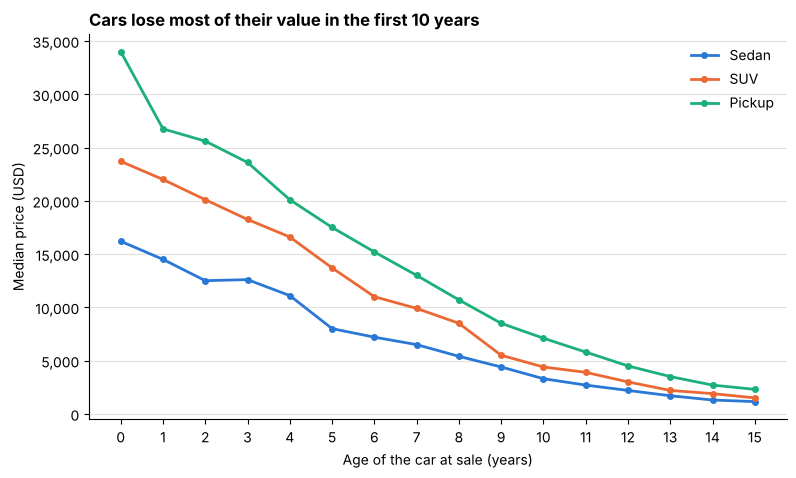

In [40]:
# Uses the price_by_age_type table from section 5.3
fig, ax = plt.subplots(figsize=(9, 5))
for car_type in main_types:
    ax.plot(price_by_age_type.index, price_by_age_type[car_type], marker="o", markersize=4, linewidth=2,
            color=TYPE_COLORS[car_type], label=car_type)

ax.yaxis.set_major_formatter(comma_format)
ax.set_xticks(range(0, 16))
ax.set_xlabel("Age of the car at sale (years)")
ax.set_ylabel("Median price (USD)")
ax.set_title("Cars lose most of their value in the first 10 years")
ax.grid(axis="y", color="#e1e0d9")
ax.legend()
plt.show()

### 6.2 Price distribution by age (violin plot)

The line chart only shows the median. A violin plot shows the whole distribution: the wider the violin at a given height, the more cars sold at that price. The small box inside is a box plot (median and quartiles). I show prices up to $60,000, which covers almost all sales, so the chart stays readable.

Sales shown in the chart: 99.7%


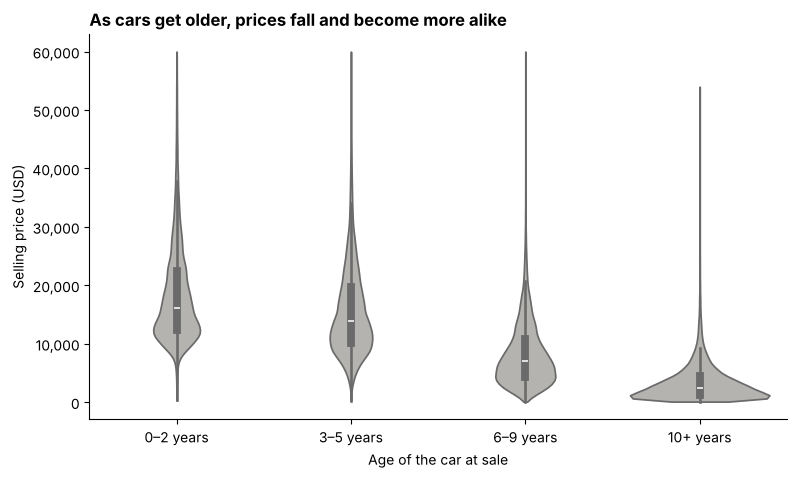

In [41]:
up_to_60k = cars[cars["selling_price"] <= 60000]
print(f"Sales shown in the chart: {len(up_to_60k) / len(cars) * 100:.1f}%")

fig, ax = plt.subplots(figsize=(9, 5))
# cut=0 stops the violins at the lowest and highest real prices (no prices below 0)
sns.violinplot(data=up_to_60k, x="age_band", y="selling_price", color=LIGHT_COLOR, cut=0, ax=ax)

ax.yaxis.set_major_formatter(comma_format)
ax.set_xlabel("Age of the car at sale")
ax.set_ylabel("Selling price (USD)")
ax.set_title("As cars get older, prices fall and become more alike")
plt.show()

### 6.3 Best-selling makes (horizontal bar chart)

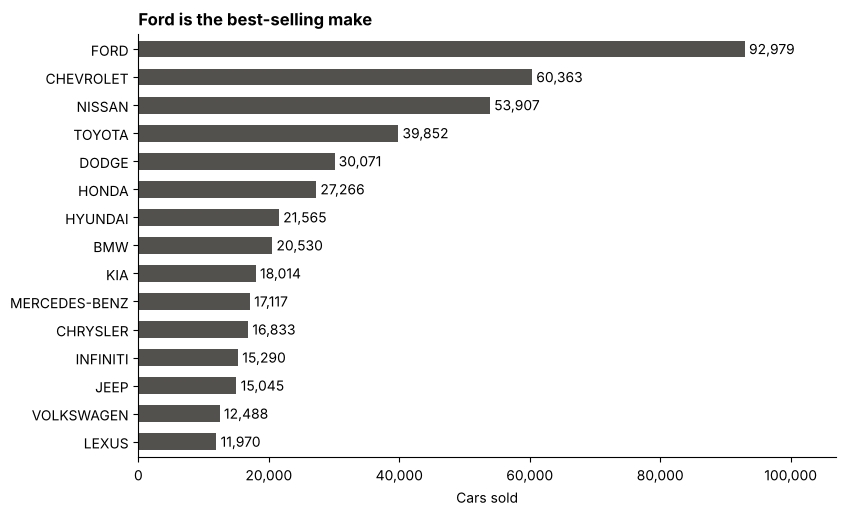

In [42]:
top_makes = by_make["cars"].head(15).sort_values()  # sorted so the biggest bar ends up at the top
top_makes.index = top_makes.index.str.upper()

ax = top_makes.plot.barh(color=NEUTRAL_COLOR, width=0.6, figsize=(9, 5.5))
ax.bar_label(ax.containers[0], labels=[f"{value:,.0f}" for value in top_makes], padding=3)

ax.set_xlim(0, top_makes.max() * 1.15)  # room for the labels at the end of the bars
ax.xaxis.set_major_formatter(comma_format)
ax.set_xlabel("Cars sold")
ax.set_ylabel("")
ax.set_title("Ford is the best-selling make")
plt.show()

### 6.4 Price by body type (box plot)

Each box goes from the first to the third quartile, and the line inside is the median. Outliers are not shown, to keep the chart readable.

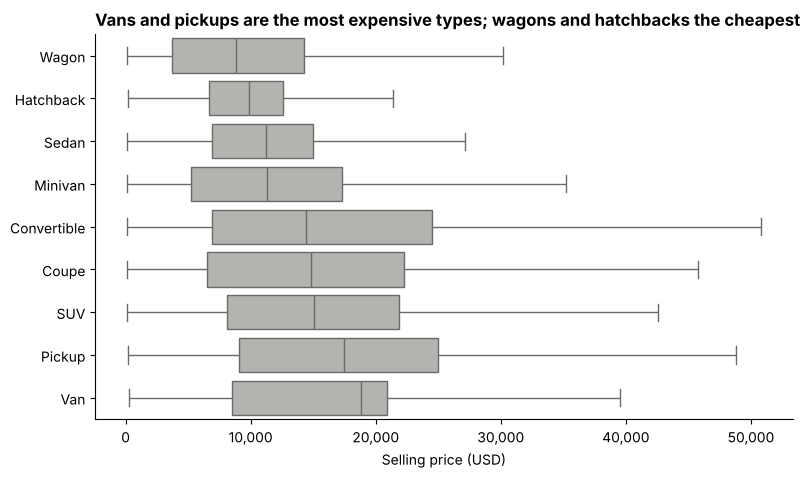

In [43]:
fig, ax = plt.subplots(figsize=(9, 5))
# by_type is already sorted from the cheapest to the most expensive type (section 5.4)
sns.boxplot(data=cars, x="selling_price", y="car_type", order=by_type.index, color=LIGHT_COLOR,
            showfliers=False, ax=ax)

ax.xaxis.set_major_formatter(comma_format)
ax.set_xlabel("Selling price (USD)")
ax.set_ylabel("")
ax.set_title("Vans and pickups are the most expensive types; wagons and hatchbacks the cheapest")
plt.show()

### 6.5 Condition and difference from market value (box plot)

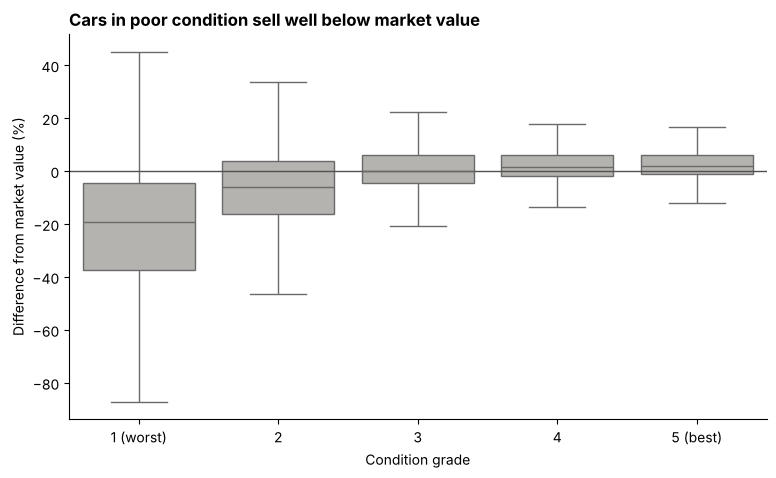

In [44]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=cars, x="condition_grade", y="market_diff_pct", color=LIGHT_COLOR, showfliers=False, ax=ax)
ax.axhline(0, color=NEUTRAL_COLOR, linewidth=1)  # 0% = sold exactly at market value

ax.set_xticks(range(5), ["1 (worst)", "2", "3", "4", "5 (best)"])
ax.set_xlabel("Condition grade")
ax.set_ylabel("Difference from market value (%)")
ax.set_title("Cars in poor condition sell well below market value")
plt.show()

### 6.6 Market value vs. selling price (scatter plot)

With more than half a million points, the chart would turn into a single blob, so I use a random sample of 5,000 sales. If every car sold exactly at market value, all points would sit on the gray line.

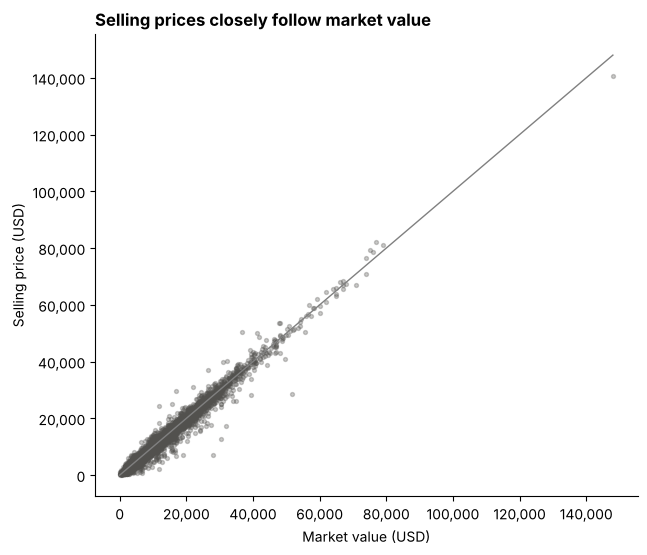

In [45]:
sample = cars.sample(5000, random_state=42)  # fixed random_state: always the same sample

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(sample["market_value"], sample["selling_price"], s=8, alpha=0.3, color=NEUTRAL_COLOR)

# Reference line where selling price = market value
max_value = sample[["market_value", "selling_price"]].max().max()
ax.plot([0, max_value], [0, max_value], color="gray", linewidth=1)

ax.xaxis.set_major_formatter(comma_format)
ax.yaxis.set_major_formatter(comma_format)
ax.set_xlabel("Market value (USD)")
ax.set_ylabel("Selling price (USD)")
ax.set_title("Selling prices closely follow market value")
plt.show()

### 6.7 Correlation between variables (heatmap)

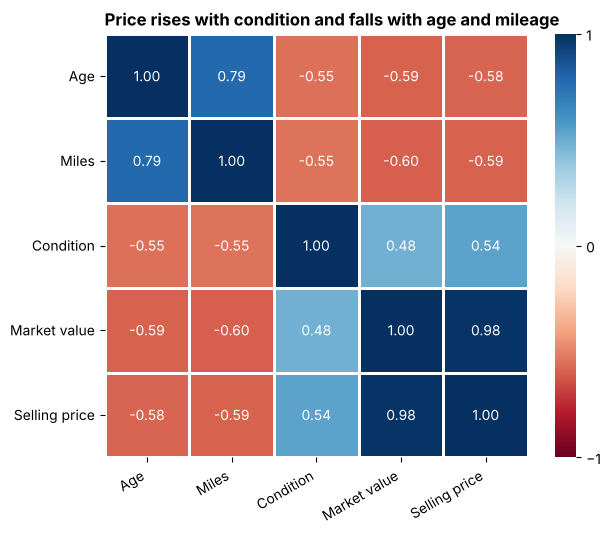

In [46]:
column_labels = ["Age", "Miles", "Condition", "Market value", "Selling price"]

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="RdBu", vmin=-1, vmax=1, square=True,
            xticklabels=column_labels, yticklabels=column_labels, linewidths=1,
            cbar_kws={"ticks": [-1, 0, 1]}, ax=ax)
plt.xticks(rotation=30, ha="right")  # tilted so long labels do not overlap
plt.yticks(rotation=0)
ax.set_title("Price rises with condition and falls with age and mileage")
plt.show()

### 6.8 Relationships between variables by car type (pair plot)

A pair plot shows a scatter plot for every pair of variables, and the distribution of each variable on the diagonal. I use a sample of 2,000 cars from the three best-selling types.

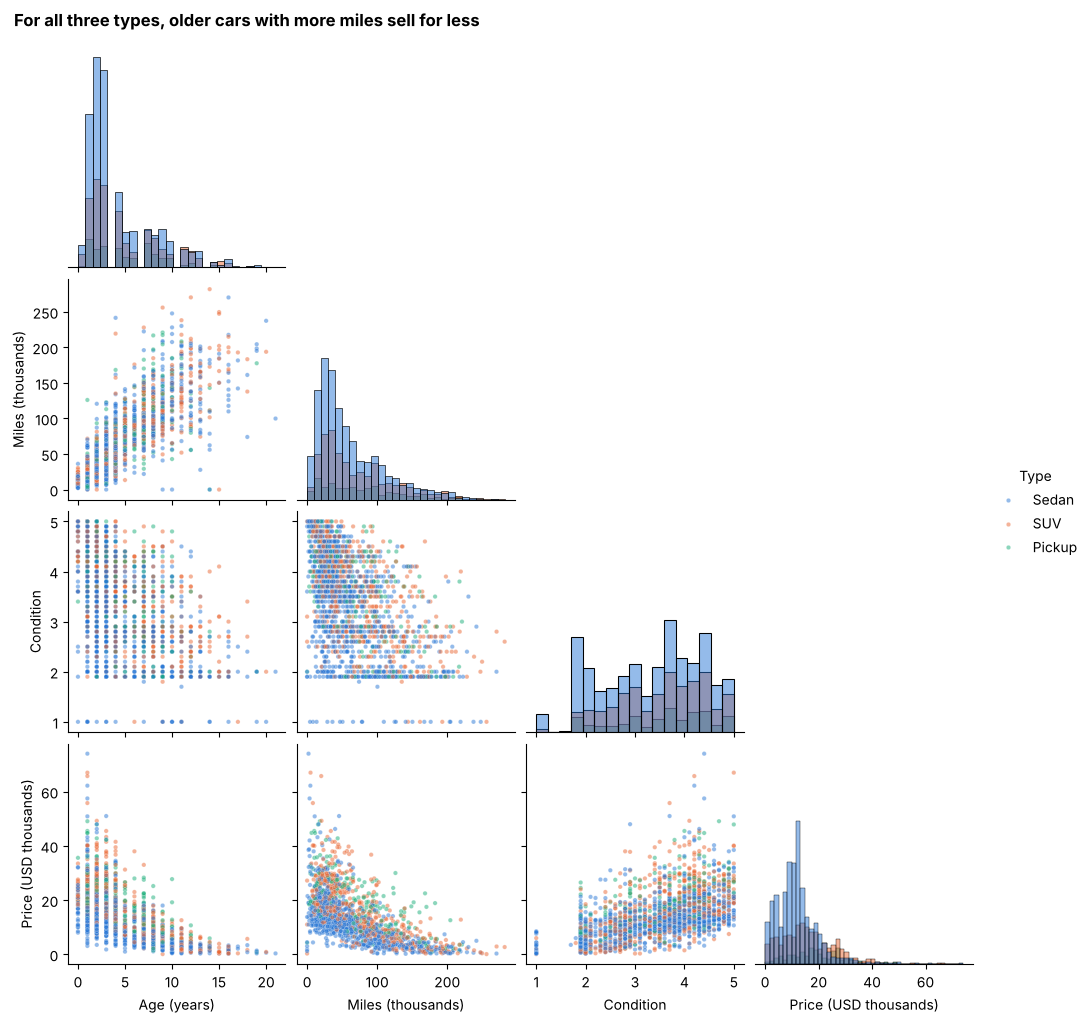

In [47]:
type_sample = (
    cars[cars["car_type"].isin(main_types)]
    .dropna(subset=["odometer", "condition"])
    .sample(2000, random_state=42)
)

# Miles and price in thousands so the axis numbers do not overlap; column names become the axis labels
plot_data = pd.DataFrame({
    "Age (years)": type_sample["age"],
    "Miles (thousands)": type_sample["odometer"] / 1000,
    "Condition": type_sample["condition"],
    "Price (USD thousands)": type_sample["selling_price"] / 1000,
    "Type": type_sample["car_type"],
})

grid = sns.pairplot(
    plot_data, hue="Type", hue_order=main_types, palette=TYPE_COLORS, corner=True,
    diag_kind="hist", plot_kws={"s": 10, "alpha": 0.5},
)
grid.figure.suptitle("For all three types, older cars with more miles sell for less",
                     x=0.02, ha="left", y=1.02, fontweight="bold")
plt.show()

### 6.9 Sales by state (map)

The file `us_states.geojson` contains the state boundaries (Natural Earth, public domain). I join the number of sales to it using the state code. The map shows the 48 contiguous states only: Hawaii and Puerto Rico have sales but are left out of the map, and Alaska has none.

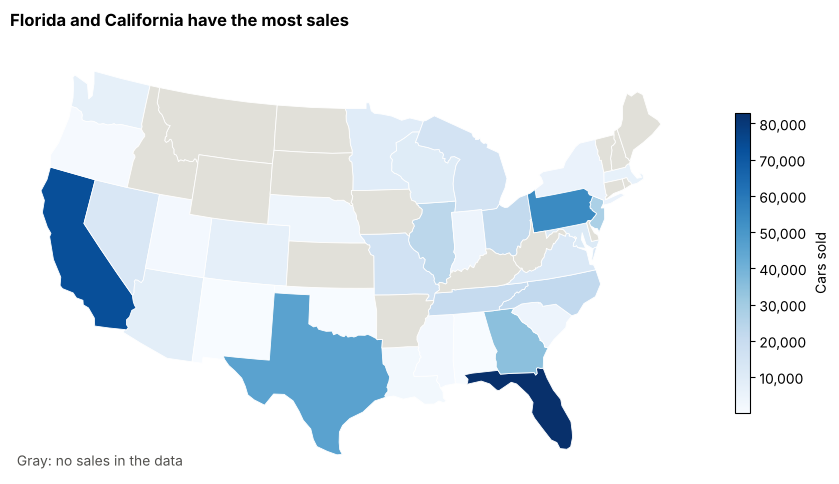

In [48]:
states_map = gpd.read_file("us_states.geojson")

# State codes are lower case in the sales data ("fl") and upper case in the map file ("FL")
sales_by_state = by_state["cars"].rename("sales").reset_index()
sales_by_state["postal"] = sales_by_state["state"].str.upper()

us_map = states_map.merge(sales_by_state, on="postal", how="left")
us_map = us_map[~us_map["postal"].isin(["AK", "HI"])]  # keep the 48 contiguous states
us_map = us_map.to_crs(epsg=5070)  # map projection commonly used for the USA

fig, ax = plt.subplots(figsize=(11, 6.5))
us_map.plot(
    column="sales", cmap="Blues", edgecolor="white", linewidth=0.6, legend=True, ax=ax,
    missing_kwds={"color": "#e1e0d9"},  # states with no sales
    legend_kwds={"label": "Cars sold", "shrink": 0.6, "format": comma_format},
)
ax.set_axis_off()
ax.set_title("Florida and California have the most sales")
ax.text(0.01, 0.02, "Gray: no sales in the data", transform=ax.transAxes, color=NEUTRAL_COLOR)
plt.show()

## 7. Key Findings and Business Recommendations

**1. Price follows market value, unless the car is in poor condition.** The correlation between selling price and market value is 0.98, and the median difference is −0.4%. However, cars with condition grade 1 sold 19.3% below market value, and grade 2 cars 5.9% below. For buyers, the condition report is the piece of information most likely to move the price away from the reference. For sellers, repairing a car before auction may pay off if the repair costs less than that gap.

**2. A car loses about 80% of its value in 10 years.** This holds for sedans (−79.6%), SUVs (−81.4%) and pickups (−79.1%). Pickups lose the most in the first year (−21.3%, compared with −10.5% for sedans and −7.2% for SUVs). Pickups and SUVs are worth more than sedans at every age.

**3. A few makes account for a large share of sales.** Ford, Chevrolet and Nissan make up 37.5% of cars sold. Luxury brands sell fewer cars, but their median price is about twice that of mainstream brands.

**4. Sales are concentrated in a few states.** Florida, California and Pennsylvania together account for 38.0% of sales. Median prices vary widely between states ($7,300 to $16,000 among the ten states with the most sales), but the gap most likely comes from the kind of cars sold at each auction.

These findings describe associations in the data. They do not prove that one variable causes another: for example, older cars also have more miles and worse condition, and all three affect the price at the same time.

## 8. Limitations and Final Conclusion

**Limitations**

- **Short and uneven period.** Sales run from December 2014 to July 2015, and some months have almost no data, so trends and seasonality cannot be analyzed.
- **Inferred condition scale.** There is no official data dictionary. The 1–5 scale is inferred from the data, although the evidence is strong.
- **No costs or margins.** The data has selling prices but not what each seller paid for the car, so profit cannot be analyzed.
- **Sales in Canada excluded.** They were 1% of sales and may have been in a different currency.
- **Missing values.** Transmission is missing for 10.8% of cars and body type for 2.2%. These cars are left out of the analyses of those columns.
- **State of the auction.** The state is where the auction took place, not where the buyer lives or where the car will be driven.

**Conclusion**

At used car auctions, prices are very predictable: they follow the reference market value and fall with age and mileage. Condition is the factor that moves prices furthest from that reference. Cleaning was an important part of the work: confirming the condition scale, removing impossible prices and misaligned rows, and finding that repeated VINs were resales rather than duplicates.

With cost data, this analysis could move from prices to profitability by car type, make or state.